# Chapitre 8 - Exercices 8.1 à 8.4

* **8.1** - Inégalité de Jensen et maximum de $R(\theta', \theta)$.
* **8.2** - L'étape E comme maximisation sous contrainte (multiplicateurs de Lagrange).
* **8.3** - Estimation de densités marginales à partir d'un échantillonneur de Gibbs.
* **8.4** - Bagging d'un lisseur linéaire avec le bootstrap paramétrique.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import ch08_inference as inf
set_style()
rng = np.random.RandomState(0)

## Exercice 8.1 : Jensen et maximisation de $E_q \log[r(Y)/q(Y)]$

**Énoncé.** Soient $r$ et $q$ deux densités de probabilité. L'inégalité de Jensen affirme
que, pour une variable aléatoire $X$ et une fonction convexe $\varphi$,
$E[\varphi(X)] \ge \varphi(E[X])$. En déduire que

$$E_q\log\frac{r(Y)}{q(Y)} \qquad \text{(éq. (8.61) du livre)}$$

(espérance prise pour $Y$ de densité $q$) est maximale, comme fonction de $r$, lorsque
$r = q$. En déduire l'inégalité $R(\theta, \theta) \ge R(\theta', \theta)$ utilisée
après l'équation (8.46).

### Rappels

* Une fonction $\varphi$ est **convexe** si
  $\varphi(tx + (1-t)y) \le t\varphi(x) + (1-t)\varphi(y)$ pour $t \in [0,1]$ ; une
  fonction deux fois dérivable est convexe si et seulement si $\varphi'' \ge 0$.
  Ici $\varphi(u) = -\log u$ sur $]0, +\infty[$ : $\varphi''(u) = 1/u^2 > 0$, donc
  $-\log$ est **strictement** convexe.
* Dans l'algorithme EM (section 8.5.2), $R(\theta', \theta) = E[\ell_1(\theta'; Z^m\mid Z)
  \mid Z, \theta]$, où $\ell_1(\theta'; Z^m\mid Z) = \log\Pr(Z^m\mid Z, \theta')$ :
  c'est l'espérance, sous la loi conditionnelle de paramètre $\theta$, du logarithme de
  la densité conditionnelle de paramètre $\theta'$.

### Solution : maximum en $r = q$

Notons $A = \{y : q(y) > 0\}$ le support de $q$. Sous $q$, $Y \in A$ presque sûrement et
la variable $X = r(Y)/q(Y)$ est bien définie, à valeurs dans $[0, +\infty[$ (si $X$ peut
valoir 0, $\log X = -\infty$ et l'inégalité ci-dessous est triviale).

1. On applique Jensen à la fonction convexe $\varphi = -\log$ :
   $E_q[-\log X] \ge -\log E_q[X]$, c'est-à-dire
   $$E_q\log\frac{r(Y)}{q(Y)} \le \log E_q\Big[\frac{r(Y)}{q(Y)}\Big].$$
2. On calcule l'espérance de droite par la formule de transfert :
   $$E_q\Big[\frac{r(Y)}{q(Y)}\Big] = \int_A \frac{r(y)}{q(y)}\,q(y)\,dy = \int_A r(y)\,dy
   \le \int r(y)\,dy = 1.$$
3. Le logarithme étant croissant, $\log E_q[r/q] \le \log 1 = 0$. Donc, **pour toute
   densité** $r$ :
   $$E_q\log\frac{r(Y)}{q(Y)} \le 0.$$
4. Pour $r = q$, le rapport vaut 1 et $E_q\log 1 = 0$ : la borne est atteinte. Le maximum
   sur $r$ vaut donc $0$ et il est atteint en $r = q$.

**Unicité.** $-\log$ étant strictement convexe, l'égalité dans Jensen impose que $X$ soit
presque sûrement constante, $r = c\,q$ sur $A$ ; l'égalité dans l'étape 2 impose
$\int_A r = 1$, d'où $c = 1$ : $r = q$ presque partout.

> **Remarque.** La quantité $-E_q\log(r/q) = \int q\log(q/r) \ge 0$ est la **divergence
> de Kullback-Leibler** $\mathrm{KL}(q\,\|\,r)$ : nous venons de démontrer
> l'**inégalité de Gibbs**, $\mathrm{KL}(q\|r) \ge 0$ avec égalité ssi $r = q$.

### Conséquence pour EM

Fixons $\theta$ et $\theta'$. Notons $q(z^m) = \Pr(z^m\mid Z, \theta)$ et
$r(z^m) = \Pr(z^m\mid Z, \theta')$, deux densités (ou fonctions de masse) en $z^m$. Par
définition de $R$ et par linéarité de l'espérance,

$$R(\theta', \theta) - R(\theta, \theta) = E_q[\log r(Z^m)] - E_q[\log q(Z^m)]
= E_q\log\frac{r(Z^m)}{q(Z^m)} \le 0,$$

d'après ce qui précède (le raisonnement est identique avec des sommes pour des variables
discrètes). Donc $R(\theta, \theta) \ge R(\theta', \theta)$ pour tout $\theta'$.

### Vérification numérique 1 : lois discrètes

On tire une loi $q$ sur 6 points et 2000 lois $r$ aléatoires ; toutes vérifient
$E_q\log(r/q) \le 0$, et la valeur se rapproche de 0 quand $r$ se rapproche de $q$.

In [2]:
q = rng.dirichlet(np.ones(6))
vals, dists = [], []
for _ in range(2000):
    t = rng.rand()                                   # r = mélange entre q et une loi aléatoire
    r = (1 - t) * q + t * rng.dirichlet(np.ones(6))
    vals.append(np.sum(q * np.log(r / q)))
    dists.append(np.abs(r - q).sum())
print("max de E_q log(r/q) sur les 2000 lois : %.2e" % max(vals))

max de E_q log(r/q) sur les 2000 lois : -1.62e-09


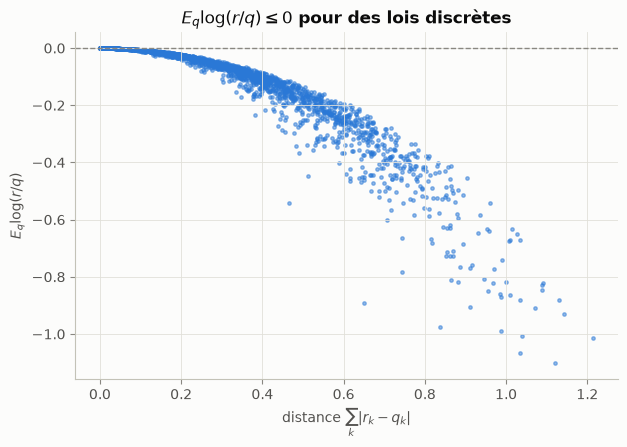

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(dists, vals, s=6, color=BLUE, alpha=0.5)
ax.axhline(0, color=GRAY, ls="--", lw=1)
ax.set(title=r"$E_q\log(r/q) \leq 0$ pour des lois discrètes",
       xlabel=r"distance $\sum_k |r_k - q_k|$", ylabel=r"$E_q\log(r/q)$")
plt.show()